QUESTION 2: CLASSIFICATION

In [1]:
#import frameworks
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
sns.set_theme(style="whitegrid")

In [2]:
#load and inspect data
titanic_data = r"C:\Users\Del\Downloads\Titanic.csv"
df = pd.read_csv(titanic_data)

print("Dimensions:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.head()

Dimensions: (891, 12)

Data types:
 PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

Missing values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Duplicate rows: 0


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
#data wrangling
data = df[["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]].copy()

data["Age"] = data["Age"].fillna(data["Age"].median())
data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])

data["Sex"] = data["Sex"].map({"male": 0, "female": 1})
data = pd.get_dummies(data, columns=["Embarked"], drop_first=True, dtype=int)

print("Missing values left:", data.isna().sum().sum())
data.head()

Missing values left: 0


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,1
1,1,1,1,38.0,1,0,71.2833,0,0
2,1,3,1,26.0,0,0,7.9250,0,1
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,1


EDA

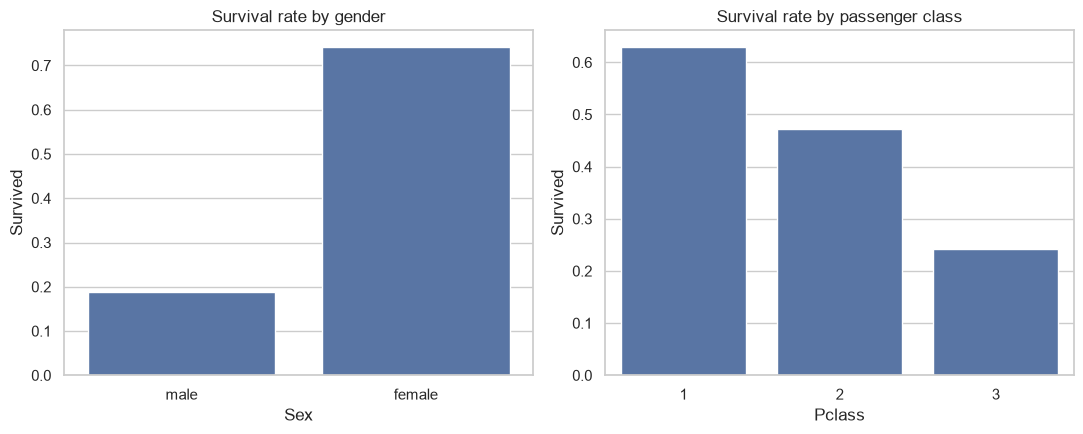

In [6]:
#barplots survival rate by gender and  class
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
sns.barplot(data=df, x="Sex", y="Survived", errorbar=None, ax=ax[0])
ax[0].set_title("Survival rate by gender")
sns.barplot(data=df, x="Pclass", y="Survived", errorbar=None, ax=ax[1])
ax[1].set_title("Survival rate by passenger class")
plt.tight_layout()
plt.show()


Women survived much more than men (about 74% against about 19%). First-class passengers had the highest survival rate (about 63%), then second class (about 47%) and third class (about 24%). So gender and passenger class had a strong effect on who survived

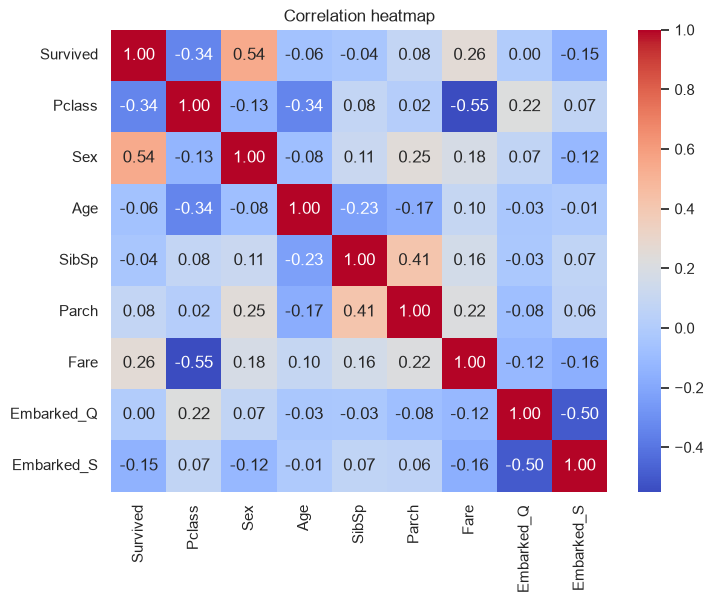

In [7]:
#correlation heatmap of features
plt.figure(figsize=(8, 6))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()


Sex has the strongest positive correlation with Survived (0.54), meaning women were more likely to survive. Pclass has a negative correlation with Survived (about -0.34), meaning passengers in a lower class (a higher class number) were less likely to survive. Fare has a weak positive correlation (about 0.26), because people who paid more were mostly in first class. Age has almost no correlation with survival

In [8]:
#model building
X = data.drop(columns="Survived")
y = data["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

log_reg = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_s, y_train)
rf = RandomForestClassifier(n_estimators=300, max_depth=6, random_state=42).fit(X_train, y_train)


In [9]:
#prediction and evaluation
models = {"Logistic Regression": log_reg.predict(X_test_s),
          "Random Forest": rf.predict(X_test)}

for name, pred in models.items():
    print("=" * 50)
    print(name)
    print("Accuracy:", round(accuracy_score(y_test, pred), 4))
    print("Confusion matrix:\n", confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, target_names=["Died", "Survived"]))

Logistic Regression
Accuracy: 0.8045
Confusion matrix:
 [[98 12]
 [23 46]]
              precision    recall  f1-score   support

        Died       0.81      0.89      0.85       110
    Survived       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

Random Forest
Accuracy: 0.8045
Confusion matrix:
 [[101   9]
 [ 26  43]]
              precision    recall  f1-score   support

        Died       0.80      0.92      0.85       110
    Survived       0.83      0.62      0.71        69

    accuracy                           0.80       179
   macro avg       0.81      0.77      0.78       179
weighted avg       0.81      0.80      0.80       179



Both models reached an accuracy of about 80.4% on the test data. Logistic Regression correctly predicted 98 passengers who died and 46 who survived. Random Forest correctly predicted 101 who died and 43 who survived. Random Forest was slightly better at finding those who died (recall 0.92), while Logistic Regression was slightly better at finding those who survived (recall 0.67 against 0.62). Both models predict deaths better than survival, because more passengers died in the data. Overall, the two models perform about the same